# Single-cell analysis of an FFPE breast tumour (10x Chromium Flex)

**Goal**: go from the raw count matrix to a UMAP annotated by cell type, with quality-control thresholds justified by the data. The annotated object is then used as the reference for spot deconvolution (RCTD).

**Data**: Janesick et al., *Nature Communications* 2023 (GEO GSE243280), Chromium Flex profiling of an FFPE breast cancer block. Cell labels published by 10x are used only to check the analysis, never to drive it.

The pipeline scripts `bin/qc_sc.py` and `bin/annotate_sc.py` implement the same steps; this notebook explores them step by step on the data.

## 0. Setup

Paths are built from the repository root (the folder containing `envs/python.yml`), so the notebook runs from any working directory.

In [35]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import scanpy as sc

# Repository root = the first parent folder that contains envs/python.yml
ROOT = Path.cwd()
while not (ROOT / "envs" / "python.yml").exists():
    if ROOT == ROOT.parent:   # reached "/" without finding it
        raise FileNotFoundError("Run this notebook from inside the repository")
    ROOT = ROOT.parent
DATA = ROOT / "data"
FIG = ROOT / "notebooks" / "figures"
FIG.mkdir(parents=True, exist_ok=True)

sc.settings.verbosity = 1
sc.settings.set_figure_params(dpi=80, frameon=False)
SEED = 0
print("repository root:", ROOT)

repository root: /home/juliette/projets/sc-spatial-breast-cancer


## 1. Loading the count matrix

Cell Ranger outputs `filtered_feature_bc_matrix.h5`: a count matrix (number of molecules of each gene in each cell), already restricted to the barcodes it called as real cells. Each cell is identified by its **barcode**, the 16-nt sequence of the gel bead it was captured with. Scanpy reads the matrix into an **AnnData** object:

| attribute | content | here |
|---|---|---|
| `adata.X` | the cells × genes matrix | raw counts (sparse matrix) |
| `adata.obs` | a table, one row per cell | empty for now; will hold QC metrics, clusters, cell types |
| `adata.var` | a table, one row per gene | Ensembl IDs |
| `adata.obsm` | per-cell coordinates | PCA, UMAP later |
| `adata.layers` | other versions of `X` | will keep the raw counts |

`var_names_make_unique()` adds a suffix to duplicated gene symbols, which some functions cannot handle.

In [36]:
# Cell Ranger output: barcodes called as cells x genes of the Flex probe panel
adata = sc.read_10x_h5(DATA / "chromium" / "filtered_feature_bc_matrix.h5")
adata.var_names_make_unique()  # a few gene symbols are duplicated
adata

/home/juliette/miniforge3/envs/scspatial-python/lib/python3.11/site-packages/anndata/_core/anndata.py:1884: UserWarning: Variable names are not unique. To make them unique, call `.var_names_make_unique`.
  utils.warn_names_duplicates("var")
/home/juliette/miniforge3/envs/scspatial-python/lib/python3.11/site-packages/anndata/_core/anndata.py:1884: UserWarning: Variable names are not unique. To make them unique, call `.var_names_make_unique`.
  utils.warn_names_duplicates("var")


AnnData object with n_obs × n_vars = 30365 × 18082
    var: 'gene_ids', 'feature_types', 'genome'

**Why the matrix is sparse.** Most genes are not detected in a given cell (incomplete capture, lowly expressed genes, genes not expressed in that cell type), so only non-zero values are stored.

In [37]:
# Most genes are not detected in a given cell: the matrix is stored as sparse
print(type(adata.X))
nonzero_frac = adata.X.nnz / (adata.n_obs * adata.n_vars)
print(f"{adata.n_obs} cells, {adata.n_vars} genes, {nonzero_frac:.1%} non-zero values")

<class 'scipy.sparse._csr.csr_matrix'>
30365 cells, 18082 genes, 13.4% non-zero values


**Observations.** **30,365 cells × 18,082 genes**, with only 13.4 % non-zero values: stored as sparse, the matrix takes ~0.6 GB instead of ~2.2 GB.

Flex does not capture whole transcripts: short probes hybridise to ~18,000 targeted genes. A probe only needs a short stretch of intact RNA, so the fragmented RNA of FFPE tissue can still be measured. This is also why the matrix contains a probe panel rather than the whole transcriptome.

## 2. Quality-control metrics

A barcode may actually be an empty droplet with some ambient RNA, a damaged cell, or two cells captured together (a doublet). Three metrics are computed for each cell:
- `n_genes_by_counts`: number of detected genes;
- `total_counts`: total number of molecules;
- `pct_counts_mt`: fraction of counts coming from mitochondrial genes. A cell with a broken membrane loses its cytoplasmic RNA but keeps its mitochondria, so a high MT fraction flags damaged cells.

The Flex panel contains **11 of the 13** mitochondrial protein-coding genes (MT-CO1 and MT-ATP8 are missing), so the MT filter is meaningful here.

In [38]:
# Mitochondrial genes: a damaged cell loses cytoplasmic RNA but keeps its mitochondria,
# so a high MT fraction flags damaged cells
adata.var["mt"] = adata.var_names.str.startswith("MT-")
print("MT genes in the panel:", adata.var["mt"].sum(), list(adata.var_names[adata.var["mt"]]))

sc.pp.calculate_qc_metrics(adata, qc_vars=["mt"], percent_top=None, log1p=False, inplace=True)
adata.obs.head()

MT genes in the panel: 11 ['MT-ND1', 'MT-ND2', 'MT-CO2', 'MT-ATP6', 'MT-CO3', 'MT-ND3', 'MT-ND4L', 'MT-ND4', 'MT-ND5', 'MT-ND6', 'MT-CYB']


,n_genes_by_counts,total_counts,total_counts_mt,pct_counts_mt
AAACAAGCAAACGGGA-1,812,1145.0,41.0,3.580786
AAACAAGCAAATAGGA-1,3975,8116.0,195.0,2.402661
AAACAAGCAAATGACT-1,478,799.0,33.0,4.130163
AAACAAGCAACAAGTT-1,1104,1393.0,21.0,1.507538
AAACAAGCAACCATTC-1,2557,3811.0,87.0,2.282865


Violin plots show the overall shape of each distribution. `total_counts` has a very long right tail that hides the low values, so the histograms below use a log scale for detected genes and zoom on 0-30 % for the MT fraction, with candidate thresholds as dashed lines.

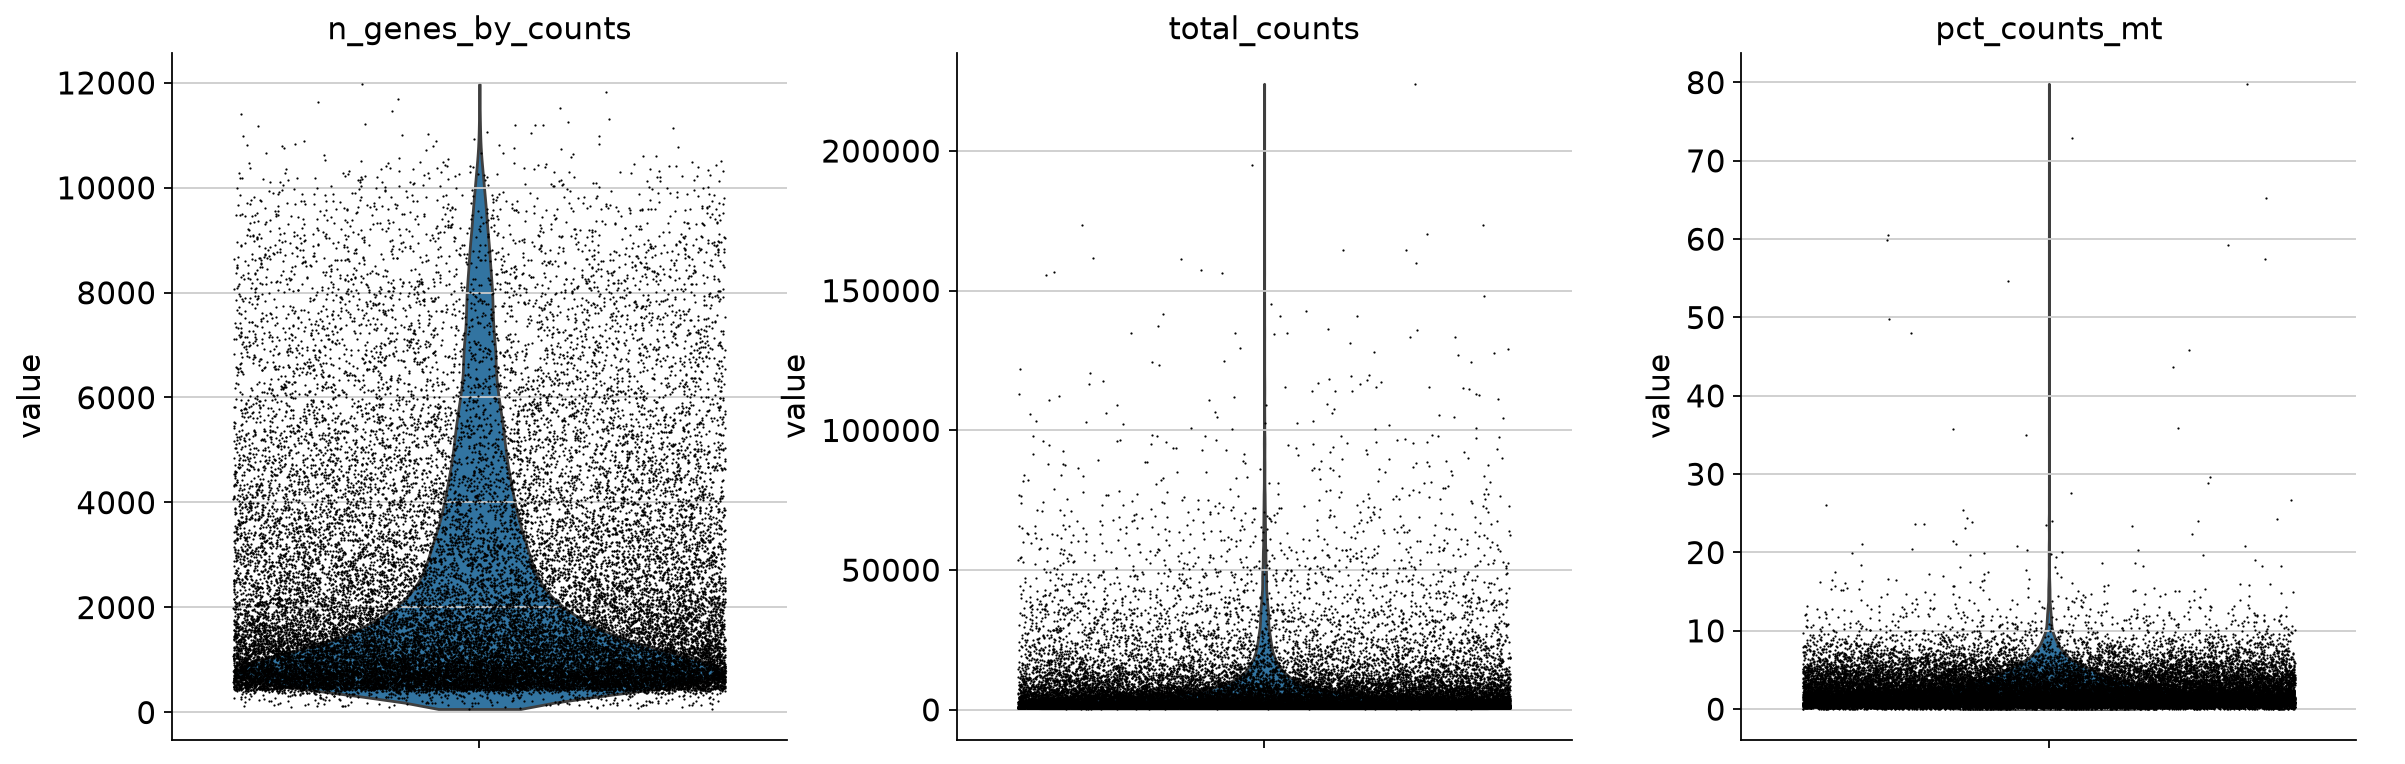

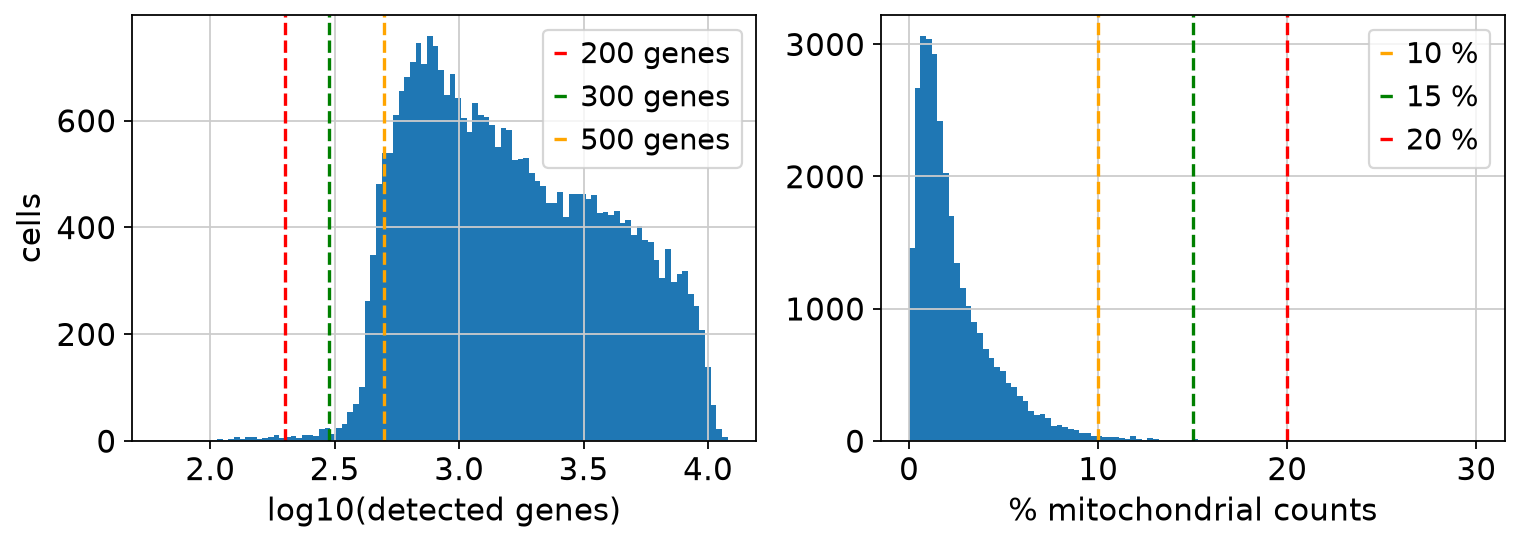

In [39]:
sc.pl.violin(adata, ["n_genes_by_counts", "total_counts", "pct_counts_mt"],
             jitter=0.4, multi_panel=True)

# Log scale for genes (long right tail), zoom on 0-30 % for MT
fig, axes = plt.subplots(1, 2, figsize=(11, 3.5))

axes[0].hist(np.log10(adata.obs["n_genes_by_counts"]), bins=100)
for cut, color in [(200, "red"), (300, "green"), (500, "orange")]:
    axes[0].axvline(np.log10(cut), color=color, ls="--", label=f"{cut} genes")
axes[0].set_xlabel("log10(detected genes)")
axes[0].set_ylabel("cells")
axes[0].legend()

axes[1].hist(adata.obs["pct_counts_mt"], bins=100, range=(0, 30))
for cut, color in [(10, "orange"), (15, "green"), (20, "red")]:
    axes[1].axvline(cut, color=color, ls="--", label=f"{cut} %")
axes[1].set_xlabel("% mitochondrial counts")
axes[1].legend()
fig.savefig(FIG / "01_qc_histograms.png", dpi=150, bbox_inches="tight")

## 3. Choosing the thresholds

A threshold should be justified by the data, not by habit: the aim is to count how many cells each candidate removes, and to avoid cutting through a population (a small cell type such as lymphocytes naturally has fewer detected genes than a tumour cell).

In [40]:
# How many cells would each threshold remove?
for cut in [100, 200, 300, 400, 500]:
    n_removed = (adata.obs["n_genes_by_counts"] < cut).sum()
    print(f"min_genes = {cut:>3} -> {n_removed:>5} cells removed ({n_removed / adata.n_obs:.1%})")

print()
for mt_cut in [5, 10, 15, 20]:
    n_removed = (adata.obs["pct_counts_mt"] > mt_cut).sum()
    print(f"% MT > {mt_cut:>2} -> {n_removed:>5} cells removed ({n_removed / adata.n_obs:.1%})")

min_genes = 100 ->     6 cells removed (0.0%)
min_genes = 200 ->    71 cells removed (0.2%)
min_genes = 300 ->   168 cells removed (0.6%)
min_genes = 400 ->   381 cells removed (1.3%)
min_genes = 500 ->  1789 cells removed (5.9%)

% MT >  5 ->  3568 cells removed (11.8%)
% MT > 10 ->   401 cells removed (1.3%)
% MT > 15 ->   100 cells removed (0.3%)
% MT > 20 ->    41 cells removed (0.1%)


### 3b. Which cells would these thresholds remove?

A single threshold assumes that every cell type has the same baseline. Using the labels published by 10x, I checked which cell types would be removed by a first candidate: **≥ 300 genes and ≤ 10 % MT**.

In [41]:
# Published 10x labels, aligned on our barcodes ("no label" = cells excluded by 10x)
labels = pd.read_excel(DATA / "annotations" / "Cell_Barcode_Type_Matrices.xlsx", sheet_name="scFFPE-Seq")
labels = labels.set_index("Barcode")["Annotation"]
adata.obs["label_10x"] = labels.reindex(adata.obs_names).fillna("no label")

removed = (adata.obs["n_genes_by_counts"] < 300) | (adata.obs["pct_counts_mt"] > 10)
print("cells removed:", removed.sum())

# Fraction of each cell type that would be removed
removed.groupby(adata.obs["label_10x"]).mean().sort_values(ascending=False).round(3)

cells removed: 568


label_10x
no label                   0.093
Invasive Tumor             0.035
Prolif Invasive Tumor      0.029
T Cell & Tumor Hybrid      0.017
DCIS 2                     0.010
Macrophages 1              0.006
Myoepi ACTA2+              0.006
Stromal                    0.005
Stromal & T Cell Hybrid    0.005
B Cells                    0.004
Endothelial                0.004
Myoepi KRT15+              0.003
DCIS 1                     0.002
CD8+ T Cells               0.002
CD4+ T Cells               0.001
Macrophages 2              0.001
Mast Cells                 0.000
LAMP3+ DCs                 0.000
IRF7+ DCs                  0.000
Perivascular-Like          0.000
dtype: float64

In [42]:
# Which criterion removes them? Columns: (fewer than 300 genes?, more than 10 % MT?)
pd.crosstab(adata.obs["label_10x"],
            [adata.obs["n_genes_by_counts"] < 300, adata.obs["pct_counts_mt"] > 10])

n_genes_by_counts       False       True       
pct_counts_mt           False True  False True 
label_10x                                      
B Cells                  1457     6     0     0
CD4+ T Cells             2895     4     0     0
CD8+ T Cells             1840     3     0     0
DCIS 1                   1858     4     0     0
DCIS 2                   2138    21     0     0
Endothelial              1051     4     0     0
IRF7+ DCs                 210     0     0     0
Invasive Tumor           4401   158     0     0
LAMP3+ DCs                103     0     0     0
Macrophages 1            2947    17     0     0
Macrophages 2             759     1     0     0
Mast Cells                 92     0     0     0
Myoepi ACTA2+            1228     7     0     0
Myoepi KRT15+             602     2     0     0
Perivascular-Like         285     0     0     0
Prolif Invasive Tumor    1290    39     0     0
Stromal                  2596    13     0     0
Stromal & T Cell Hybrid   424     2     0     0
T Cell & Tumor Hybrid     986    17     0     0
no label                 2635   102   167     1

- All cells with fewer than 300 genes have **no 10x label**: this threshold only removes cells the authors had already excluded.
- Labelled cells are removed **only by the MT threshold**, and mostly **invasive tumour cells**.

In [43]:
# How many invasive tumour cells does each MT threshold remove?
tumour = adata.obs["label_10x"].isin(["Invasive Tumor", "Prolif Invasive Tumor"])
for mt_cut in [10, 15, 20]:
    removed_mt = adata.obs["pct_counts_mt"] > mt_cut
    print(f"MT > {mt_cut} %: {removed_mt.sum():>4} cells in total, "
          f"of which {(removed_mt & tumour).sum():>3} invasive tumour cells")

MT > 10 %:  401 cells in total, of which 197 invasive tumour cells
MT > 15 %:  100 cells in total, of which   0 invasive tumour cells
MT > 20 %:   41 cells in total, of which   0 invasive tumour cells


/home/juliette/miniforge3/envs/scspatial-python/lib/python3.11/site-packages/anndata/_core/anndata.py:1255: ImplicitModificationWarning: Trying to modify attribute `.obs` of view, initializing view as actual.
  df[key] = c


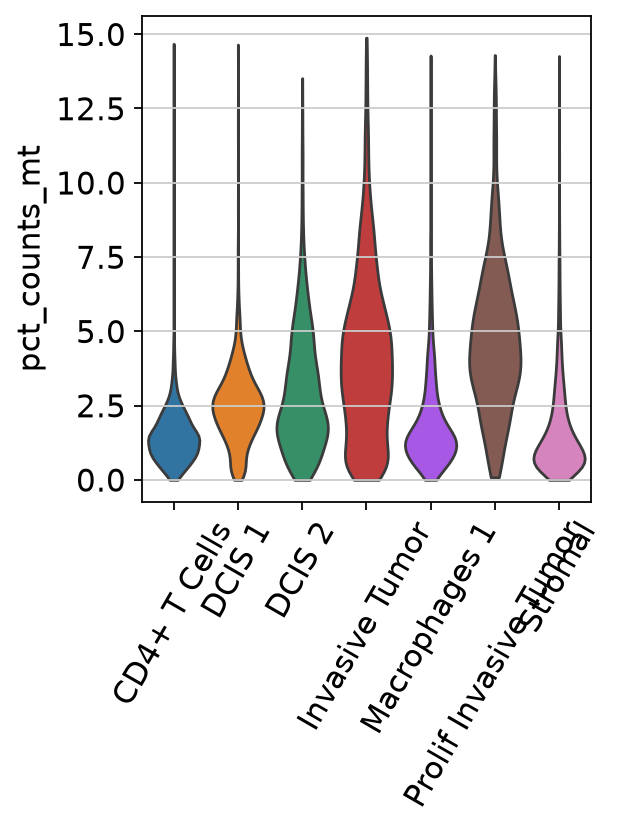

label_10x
Prolif Invasive Tumor      4.44
Invasive Tumor             3.85
T Cell & Tumor Hybrid      3.70
DCIS 2                     2.50
DCIS 1                     2.44
Myoepi KRT15+              1.97
B Cells                    1.81
Myoepi ACTA2+              1.70
Stromal & T Cell Hybrid    1.48
IRF7+ DCs                  1.47
Macrophages 1              1.44
CD4+ T Cells               1.38
Endothelial                1.33
CD8+ T Cells               1.31
Perivascular-Like          1.16
Stromal                    1.11
no label                   1.00
LAMP3+ DCs                 0.99
Mast Cells                 0.92
Macrophages 2              0.83
Name: pct_counts_mt, dtype: float32

In [44]:
# Is the baseline MT fraction the same in every cell type?
cell_types = ["Invasive Tumor", "Prolif Invasive Tumor", "DCIS 1", "DCIS 2",
              "CD4+ T Cells", "Macrophages 1", "Stromal"]
subset = adata[adata.obs["label_10x"].isin(cell_types)]
sc.pl.violin(subset, "pct_counts_mt", groupby="label_10x", rotation=60, stripplot=False, show=False)
plt.savefig(FIG / "01_mt_by_cell_type.png", dpi=150, bbox_inches="tight")
plt.show()

adata.obs.groupby("label_10x")["pct_counts_mt"].median().sort_values(ascending=False).round(2)

In [45]:
# Do invasive tumour cells with 10-15 % MT look damaged (fewer genes) or healthy?
invasive = adata.obs[adata.obs["label_10x"] == "Invasive Tumor"].copy()
invasive["mt_group"] = np.where(invasive["pct_counts_mt"] > 10, "MT 10-15 %", "MT < 10 %")
invasive.groupby("mt_group")[["n_genes_by_counts", "total_counts", "pct_counts_mt"]].median()

,n_genes_by_counts,total_counts,pct_counts_mt
mt_group,,,
MT 10-15 %,4912.5,12719.5,11.677942
MT < 10 %,3423.0,6552.0,3.733693


**Conclusion.** Invasive tumour cells have a higher baseline MT fraction (median 3.9 %, and 4.4 % for proliferating ones) than T cells, macrophages or stroma (1.1-1.4 %): their whole distribution is shifted upwards. Those between 10 and 15 % MT have **more** detected genes (median 4,913 vs 3,423) and twice as many counts: they look like large, metabolically active cells, not damaged ones. A 10 % cut-off would bias the reference against invasive tumour cells, so I use **15 %**, which removes no tumour cell. No labelled cell type goes above ~15 %, which suggests that 10x used a similar cut-off.

Applying the chosen thresholds. Genes detected in fewer than 3 cells are also removed: they carry no information and slow down the computations.

In [46]:
MIN_GENES = 300   # cuts in the sparse lower tail, before the main population
MAX_PCT_MT = 15   # see 3b: 10 % would remove healthy invasive tumour cells

n_before = adata.n_obs
sc.pp.filter_cells(adata, min_genes=MIN_GENES)
adata = adata[adata.obs["pct_counts_mt"] <= MAX_PCT_MT].copy()
# Genes detected in fewer than 3 cells carry no information
sc.pp.filter_genes(adata, min_cells=3)
print(f"{n_before} -> {adata.n_obs} cells; {adata.n_vars} genes")

30365 -> 30098 cells; 16962 genes


**Chosen thresholds.**
- **min_genes = 300**: cuts in the sparse lower tail of the distribution (log10 ≈ 2.5), before the steep rise of the main population. It removes 168 cells (0.6 %), all without a 10x label. 500 would cut into the main population (1,789 cells, 5.9 %).
- **max % MT = 15**: see 3b. 10 % would remove 197 invasive tumour cells that look healthy; 15 % removes 100 cells, none of them tumour cells.
- Result: 30,365 → **30,098 cells** (267 removed) and 16,962 genes kept (detected in ≥ 3 cells).
- In the pipeline, these values are the parameters `sc_min_genes = 300` and `sc_max_pct_mt = 15` of `nextflow.config`.

## 4. Doublets

Two cells captured in the same droplet share one barcode and look like a single cell with a mixed profile (for example T cell + tumour cell). Doublets can form artificial clusters between real populations. **Scrublet** simulates artificial doublets by adding up the counts of random pairs of real cells, places real cells and simulated doublets in the same reduced space, and gives each real cell a **doublet score**: how much its neighbourhood is made of simulated doublets.

Raw counts are saved in `adata.layers["counts"]` **before** any normalisation: Scrublet adds up counts, and RCTD (deconvolution) models raw integer counts. Once `X` is normalised and log-transformed, the original counts cannot be recovered.

predicted_doublet
False    23377
True      6721
Name: count, dtype: int64


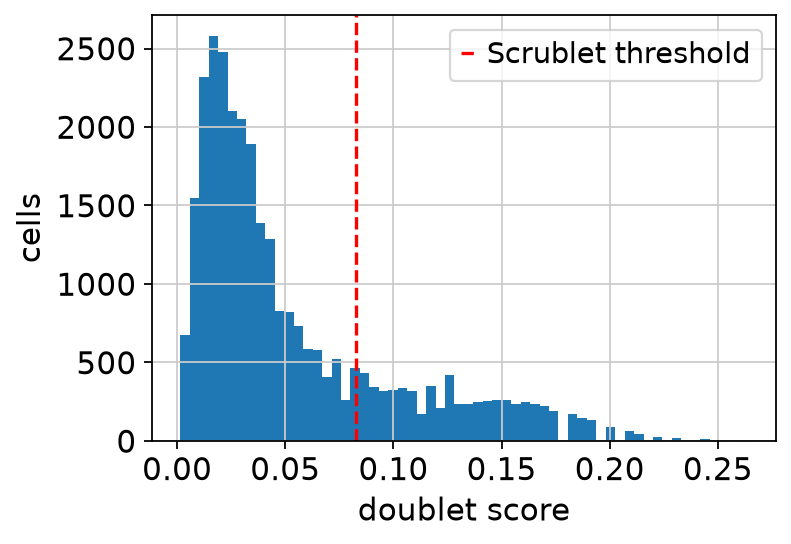

In [47]:
# Keep a COPY of the raw integer counts (a plain assignment would only create a second name
# for the same matrix, which would then change when X is normalised)
adata.layers["counts"] = adata.X.copy()

# mean_center=False keeps the matrix sparse (TruncatedSVD instead of PCA):
# with centring, Scrublet needs > 10 GB of memory on these ~30,000 cells.
# random_state fixes the random pairs of cells, so the result is reproducible.
sc.pp.scrublet(adata, mean_center=False, random_state=SEED)

# Scrublet's automatic call, and the distribution of doublet scores with its automatic threshold
print(adata.obs["predicted_doublet"].value_counts())
fig, ax = plt.subplots(figsize=(5, 3.5))
ax.hist(adata.obs["doublet_score"], bins=60)
ax.axvline(adata.uns["scrublet"]["threshold"], color="red", ls="--", label="Scrublet threshold")
ax.set_xlabel("doublet score")
ax.set_ylabel("cells")
ax.legend()
fig.savefig(FIG / "01_doublets.png", dpi=150, bbox_inches="tight")

**The automatic threshold does not fit these data.** Scrublet places its threshold in the dip between two modes (single cells with low scores, doublets with high scores). Here the distribution has **a single mode** followed by a long plateau, so the threshold (0.083) falls inside the main population and would remove **22 %** of the cells, whereas a few percent of doublets are expected.

To choose a better threshold, the cells labelled *Hybrid* by 10x (T Cell & Tumor Hybrid, Stromal & T Cell Hybrid: mixed profiles, i.e. doublets) are used as an approximate ground truth: a good threshold removes many hybrids and few other cells.

In [48]:
# Published 10x labels, put in the order of our cells (cells without a label get NaN)
labels_10x = pd.read_excel(DATA / "annotations" / "Cell_Barcode_Type_Matrices.xlsx", sheet_name="scFFPE-Seq")
labels_10x = labels_10x.set_index("Barcode")["Annotation"].reindex(adata.obs_names)
# True for the cells that 10x labelled as hybrids (their doublets)
is_hybrid = labels_10x.fillna("").str.contains("Hybrid").values

# For each candidate threshold: fraction of all cells, of hybrids and of other cells that would be removed
thresholds = [adata.uns["scrublet"]["threshold"], 0.12, 0.15, 0.18]
for t in thresholds:
    removed = (adata.obs["doublet_score"] > t).values
    print(f"threshold {t:.2f}: {removed.mean():5.1%} of cells removed | "
          f"{removed[is_hybrid].mean():4.0%} of hybrids | {removed[~is_hybrid].mean():5.1%} of other cells")

threshold 0.08: 22.3% of cells removed |  70% of hybrids | 20.0% of other cells
threshold 0.12: 13.2% of cells removed |  45% of hybrids | 11.6% of other cells
threshold 0.15:  7.0% of cells removed |  24% of hybrids |  6.1% of other cells
threshold 0.18:  2.4% of cells removed |   8% of hybrids |  2.1% of other cells


**Chosen threshold: 0.18.** At every threshold a hybrid is about 4 times more likely to be removed than another cell, so the score carries real information, but no threshold separates hybrids cleanly (catching 70 % of hybrids means discarding 20 % of the other cells). I chose a **conservative** cut-off that keeps real cells: 0.18 removes 2.4 % of the cells. Remaining doublets are expected to form their own clusters, which are identified during annotation (section 7d).

In the pipeline, this value is the parameter `sc_doublet_threshold = 0.18` of `nextflow.config`.

In [49]:
DOUBLET_THRESHOLD = 0.18

# Replace Scrublet's automatic call with the chosen threshold, then keep only the non-doublets
# (~ is the "not" operator for boolean pandas columns)
adata.obs["predicted_doublet"] = adata.obs["doublet_score"] > DOUBLET_THRESHOLD
adata = adata[~adata.obs["predicted_doublet"]].copy()   # .copy(): a real object, not a view of the old one
adata.n_obs

29387

## 5. Normalisation, highly variable genes, PCA

1. **`normalize_total`**: a cell captured twice as deeply has twice as many counts for every gene. Each cell is scaled to the same total (10,000), so that cells are compared on proportions, not on sequencing depth.
2. **`log1p`**: log(1 + x). Values range from 0 to thousands; the log compresses large values so that a handful of very highly expressed genes does not dominate the distances between cells (and log(0) is avoided).
3. **`highly_variable_genes`**: the 2,000 genes that vary most between cells. They are the ones that separate cell types; the others mostly add noise.
4. **`pca`**: summarises these 2,000 genes into 50 axes of variation. The variance plot (elbow) helps decide how many axes to keep.

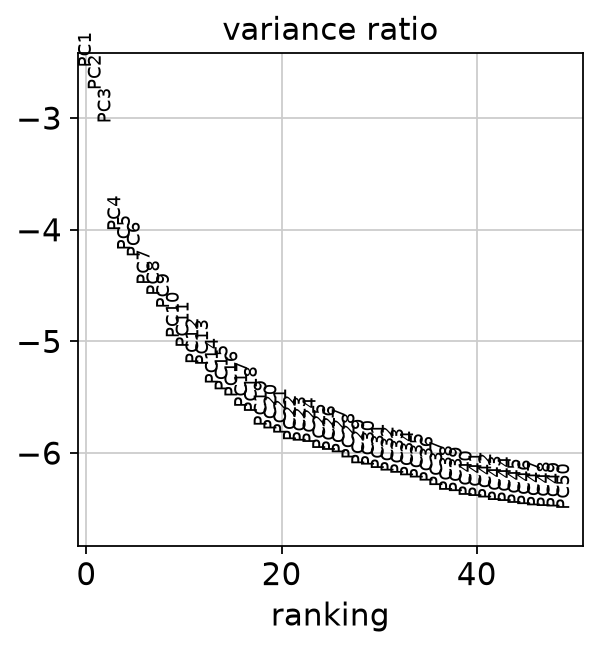

In [50]:
# 1. Same total for every cell: counts per 10,000 molecules
sc.pp.normalize_total(adata, target_sum=1e4)
# 2. log(1 + x): compresses large values
sc.pp.log1p(adata)
# 3. Flags the 2,000 most variable genes in adata.var["highly_variable"]
sc.pp.highly_variable_genes(adata, n_top_genes=2000)
# 4. PCA on these genes only; the coordinates are stored in adata.obsm["X_pca"]
sc.tl.pca(adata, n_comps=50, mask_var="highly_variable", random_state=SEED)
# Fraction of variance explained by each component (log scale), from PC1 to PC50
sc.pl.pca_variance_ratio(adata, n_pcs=50, log=True)

**Observations.** PC1 to PC3 stand well above the rest (the largest differences in the tissue: epithelium, immune cells, stroma), the curve keeps decreasing clearly until ~PC15-20, and beyond ~30 it becomes a straight, slowly decreasing line: later components mostly add noise. **30 PCs** are kept: keeping slightly more components than the elbow is safer than cutting too early and merging close cell types.

## 6. Neighbour graph, UMAP, Leiden clustering

- **`neighbors`** links each cell to its 15 most similar cells in the 30-PC space. UMAP and Leiden both work on this graph.
- **`umap`** draws the graph in 2D. Neighbouring cells on the UMAP are similar, but the distances between islands, their size and their shape carry little meaning: it is a tool to look at the data, not to measure.
- **`leiden`** splits the graph into communities (clusters) of tightly connected cells. The `resolution` sets how fine the split is; several values are compared and the one whose clusters make biological sense is kept.

resolution 0.4: 13 clusters
resolution 0.8: 23 clusters
resolution 1.2: 27 clusters


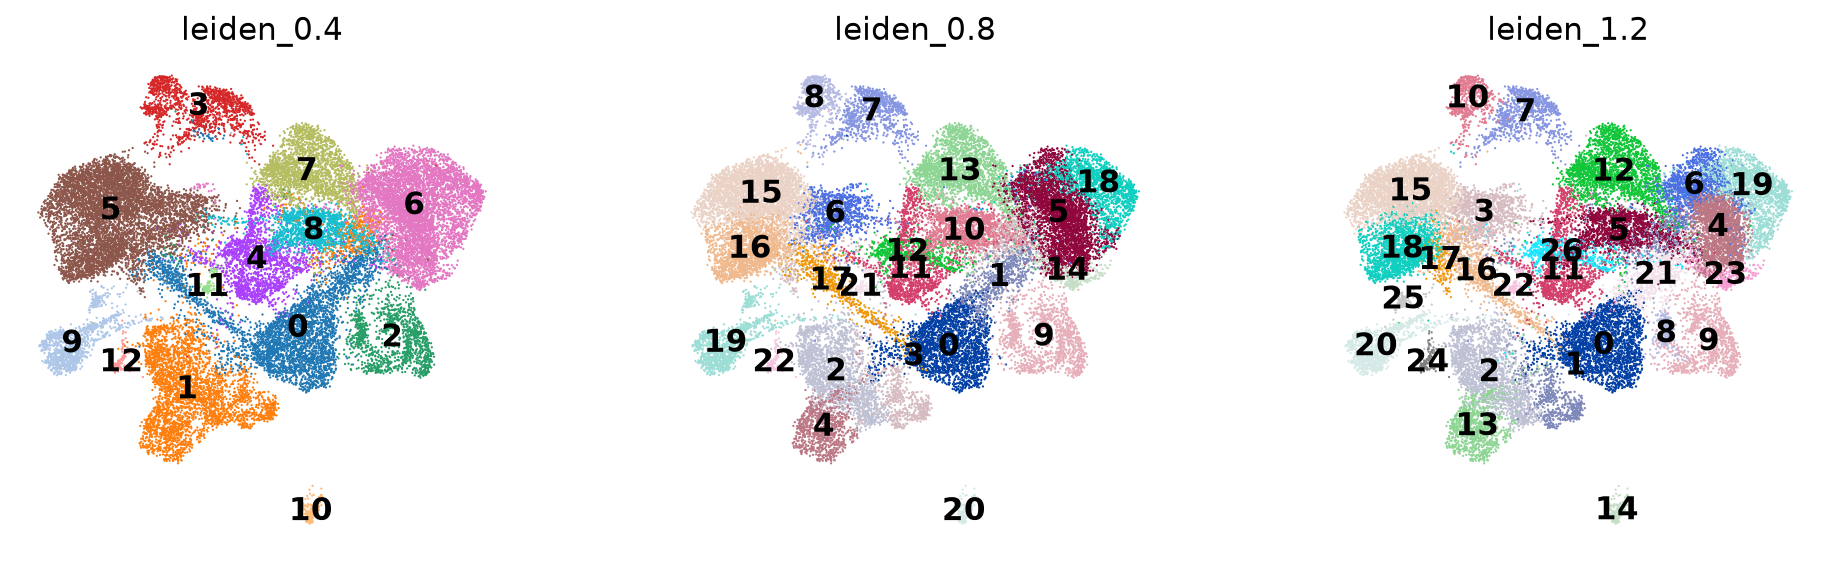

In [51]:
N_PCS = 30   # see section 5

# Graph of the 15 nearest neighbours of each cell, then the 2D UMAP layout of this graph
sc.pp.neighbors(adata, n_neighbors=15, n_pcs=N_PCS, random_state=SEED)
sc.tl.umap(adata, random_state=SEED)

# Leiden clustering at three resolutions, each stored in its own column (leiden_0.4, leiden_0.8, leiden_1.2)
for res in [0.4, 0.8, 1.2]:
    sc.tl.leiden(adata, resolution=res, key_added=f"leiden_{res}",
                 flavor="igraph", n_iterations=2, directed=False, random_state=SEED)
    print(f"resolution {res}: {adata.obs[f'leiden_{res}'].nunique()} clusters")

sc.pl.umap(adata, color=["leiden_0.4", "leiden_0.8", "leiden_1.2"], legend_loc="on data", ncols=3)

**Observations.** 13, 23 and 27 clusters at resolutions 0.4, 0.8 and 1.2. Going from 0.4 to 0.8 splits the large islands (tumour, lymphocytes) and isolates thin "bridges" between islands into their own clusters; 1.2 adds small fragments with no visible boundary, a sign of over-clustering. **Resolution 0.8** is kept.

The QC metrics below, drawn on the UMAP, help spot technical clusters: a cluster defined only by few genes or by a high doublet score is an artefact, not a cell type.

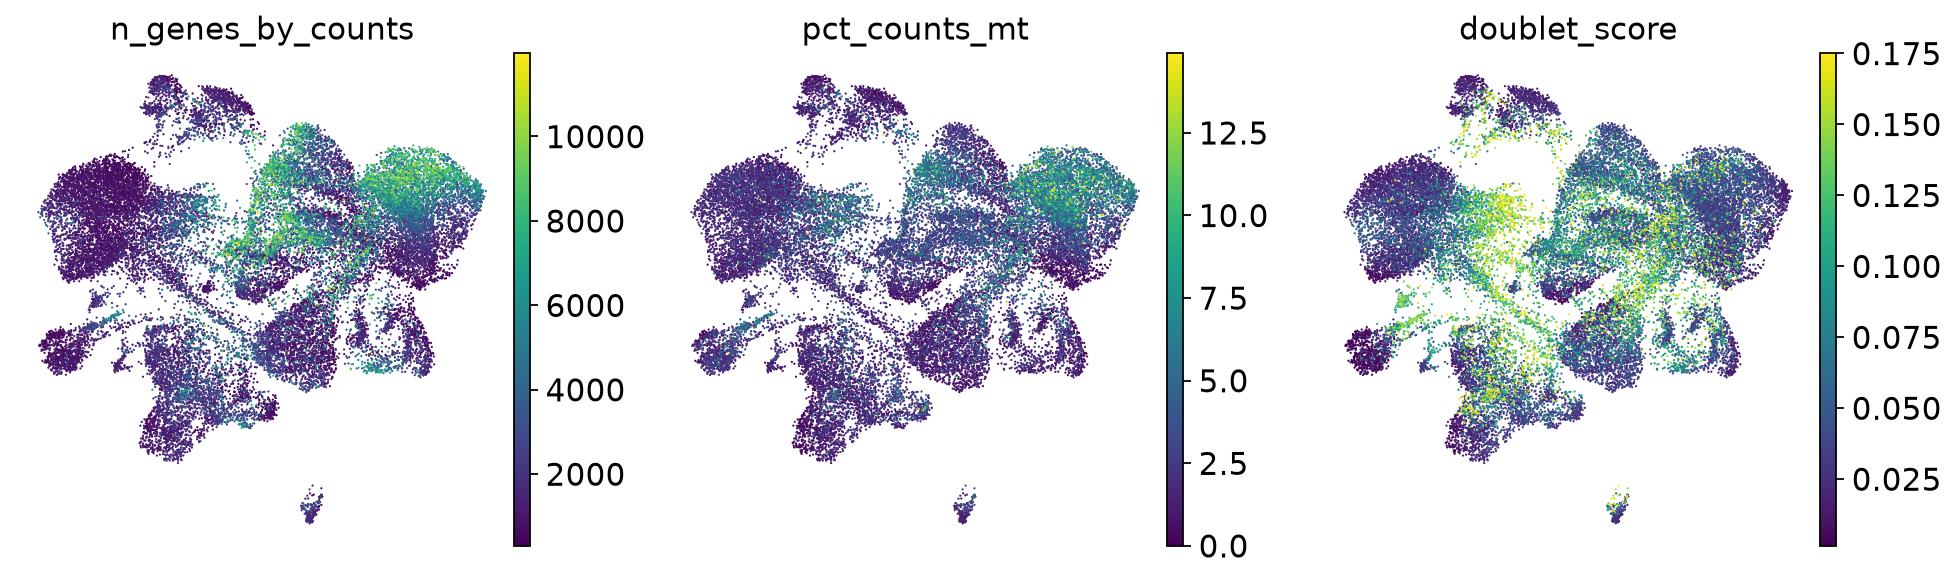

In [52]:
# Colour the UMAP by the three QC metrics
sc.pl.umap(adata, color=["n_genes_by_counts", "pct_counts_mt", "doublet_score"], ncols=3)

**Observations on the QC UMAP.** The tumour island and the top of the centre have many detected genes (6,000-10,000: large, active cells) and the highest MT fraction, as found in section 3b. The large island on the left has few genes (~1,000-2,000), the profile of small lymphocytes. The highest doublet scores are on the bridges between islands, where cells with mixed profiles are expected.

In [53]:
RESOLUTION = 0.8
# Copy the chosen clustering into a column simply named "leiden", used by all following cells
adata.obs["leiden"] = adata.obs[f"leiden_{RESOLUTION}"]

## 7. Cluster annotation

A cluster is only a number. Two complementary sources of information are used to name it:
- **7a.** the genes that the data themselves single out for each cluster (`rank_genes_groups`), interpreted with biological knowledge;
- **7b-7c.** the curated marker list `assets/markers_breast.csv` (sources and checks in `assets/MARKERS.md`): systematic and reproducible, this is what the pipeline (`bin/annotate_sc.py`) uses.

Clusters that do not fit a single cell type are then investigated (**7d**) before the final annotation (**7e**).

### 7a. Top genes per cluster

In [54]:
# Genes that best distinguish each cluster from ALL other cells (Wilcoxon rank-sum test).
# Genes shared by several clusters (e.g. EPCAM in every epithelial cluster) rank low here,
# because they do not distinguish one cluster from the others.
pd.set_option("display.max_columns", None)   # show all 23 clusters
sc.tl.rank_genes_groups(adata, groupby="leiden", method="wilcoxon")
# One column per cluster, with its 8 top genes (row 0 = best gene)
pd.DataFrame(adata.uns["rank_genes_groups"]["names"]).head(8)

/home/juliette/miniforge3/envs/scspatial-python/lib/python3.11/site-packages/scanpy/tools/_rank_genes_groups.py:458: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  self.stats[group_name, "names"] = self.var_names[global_indices]
/home/juliette/miniforge3/envs/scspatial-python/lib/python3.11/site-packages/scanpy/tools/_rank_genes_groups.py:460: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  self.stats[group_name, "scores"] = scores[global_indices]
/home/juliette/miniforge3/envs/scspatial-python/lib/python3.11/site-packages/scanpy/t

,0,1,2,3,4,5,6,7,8,9,10,11,12,13,14,15,16,17,18,19,20,21,22
0,COL3A1,COL3A1,CD74,APOE,STAB1,ERBB2,MT-CO2,IGKC,IGHA1,IGFBP7,CEACAM6,KRT5,MGP,CPB1,MLPH,IL7R,KLRK1,COL3A1,DCAF7,MS4A1,IRF8,CPA3,BIRC3
1,COL1A2,COL1A1,LYZ,IFI30,CD163,DCAF7,MT-CO3,TXNDC5,JCHAIN,COL4A2,TTC3,TAGLN,KRT15,TFF3,VMP1,TRAC,CCL5,COL1A1,MKI67,CIITA,MPEG1,KIT,KDM2B
2,COL1A1,COL1A2,CIITA,CTSB,MS4A7,VMP1,MT-ND4L,MZB1,TXNDC5,COL4A1,SLC12A2,KRT14,LTF,CD24,ANKRD30A,CD2,CD96,COL1A2,HIST1H1B,CD74,IRF7,HDC,LAMP3
3,COL6A3,COL6A3,ITGAX,FTL,DAB2,STARD3,MIEN1,SSR4,MZB1,SPARC,AGR2,TPM1,GABRP,CYB561,FASN,ARHGEF1,CD2,COL6A3,HSP90AA1,BANK1,CLEC4C,IL1RL1,CSF2RA
4,COL6A2,POSTN,MS4A6A,PSAP,PDK4,PGAP3,IL7R,ITM2C,IGKC,A2M,ZNF652,DST,SFRP1,TFF1,ERBB2,TMC8,AKNA,COL6A2,ZWINT,CD22,PTPRS,MS4A2,RGS1
5,COL6A1,DCAF7,FGL2,CD68,MS4A6A,ANKRD30A,ERBB2,PIM2,SSR4,VIM,ITGB6,MYLK,WFDC2,SLC39A6,STARD3,TXNIP,ARHGEF1,DCN,RRM2,CD37,NIBAN3,VWA5A,CD83
6,DCN,MIEN1,SPI1,CTSD,CSF1R,FASN,CD2,JCHAIN,ITM2C,CDH5,SPOP,KRT17,CD24,CEACAM6,DCAF7,IKZF1,CXCR4,POSTN,NUSAP1,BLK,GZMB,STX3,DAPP1
7,POSTN,FN1,CSF2RA,GPNMB,FCGRT,MLPH,CYB561,TENT5C,DERL3,EGFL7,TFF3,ACTA2,CCL28,RHOB,PPM1D,B2M,B2M,FN1,PPM1D,PARP15,BCL11A,SLC18A2,CD74


**Observations** (interpretation of the table above):
- **Tumour epithelium**: 5 and 14 (ERBB2, STARD3, PGAP3, MIEN1: neighbouring genes of the **ERBB2/HER2 amplicon** on chromosome 17, co-amplified in this HER2+ tumour), 18 (MKI67, RRM2, ZWINT: proliferating tumour cells), 10 (CEACAM6, AGR2, TFF3) and 13 (TFF1, TFF3, CPB1: luminal, oestrogen-responsive genes).
- **Myoepithelium**: 11 (KRT5, KRT14, KRT17, ACTA2) and 12 (KRT15, LTF, GABRP).
- **Stroma**: fibroblasts 0, 1 and 17 (collagens, DCN, POSTN); endothelium 9 (CDH5, EGFL7, COL4A1/2).
- **Immune cells**: T cells 15 (IL7R, TRAC) and 16 (CCL5, KLRK1: cytotoxic); B cells 19 (MS4A1, BANK1); plasma cells 7 and 8 (IGKC, JCHAIN, MZB1; IGHA1 in 8); macrophages 3 (APOE, CD68) and 4 (CD163, STAB1); myeloid cells 2 (CD74, LYZ, ITGAX); plasmacytoid DCs 20 (CLEC4C, IRF7), mast cells 21 (CPA3, KIT, HDC), LAMP3+ DCs 22 (LAMP3, CD83).
- **Suspicious**: 6 mixes MT genes, T-cell genes (IL7R, CD2) and tumour genes (ERBB2, MIEN1); 1 has tumour genes (DCAF7, MIEN1) among fibroblast genes. Investigated in 7d.

### 7b. Curated markers

The marker list is read from `assets/markers_breast.csv` and drawn as a dotplot.

In [55]:
# Curated markers: {cell type: [genes]}, keeping only genes present in the Flex panel
markers_df = pd.read_csv(ROOT / "assets" / "markers_breast.csv")
markers = {r.cell_type: [g for g in r.genes.split(";") if g in adata.var_names] for r in markers_df.itertuples()}
markers

{'Tumor_epithelial': ['EPCAM', 'KRT8', 'KRT19', 'CDH1', 'ELF3', 'CLDN4'],
 'Myoepithelial': ['KRT5', 'KRT14', 'KRT17', 'TP63', 'KRT15'],
 'Fibroblasts': ['COL1A1', 'DCN', 'LUM', 'PDGFRA', 'FBLN1'],
 'Endothelial': ['VWF', 'CDH5', 'PLVAP', 'EMCN', 'CLDN5'],
 'Perivascular': ['RGS5', 'NOTCH3', 'CSPG4', 'MCAM'],
 'T_cells': ['CD3D', 'CD3E', 'CD2', 'TRAC'],
 'B_cells': ['MS4A1', 'CD79A', 'CD79B', 'CD19', 'BANK1'],
 'Plasma_cells': ['JCHAIN', 'IGKC', 'IGHA1', 'MZB1', 'TNFRSF17'],
 'Macrophages': ['CD163', 'C1QA', 'C1QB', 'MS4A7', 'CSF1R'],
 'Plasmacytoid_DC': ['LILRA4', 'CLEC4C', 'PTCRA', 'IL3RA'],
 'LAMP3_DC': ['LAMP3', 'IDO1', 'CCR7', 'FSCN1'],
 'Mast_cells': ['CPA3', 'MS4A2', 'HDC', 'KIT']}

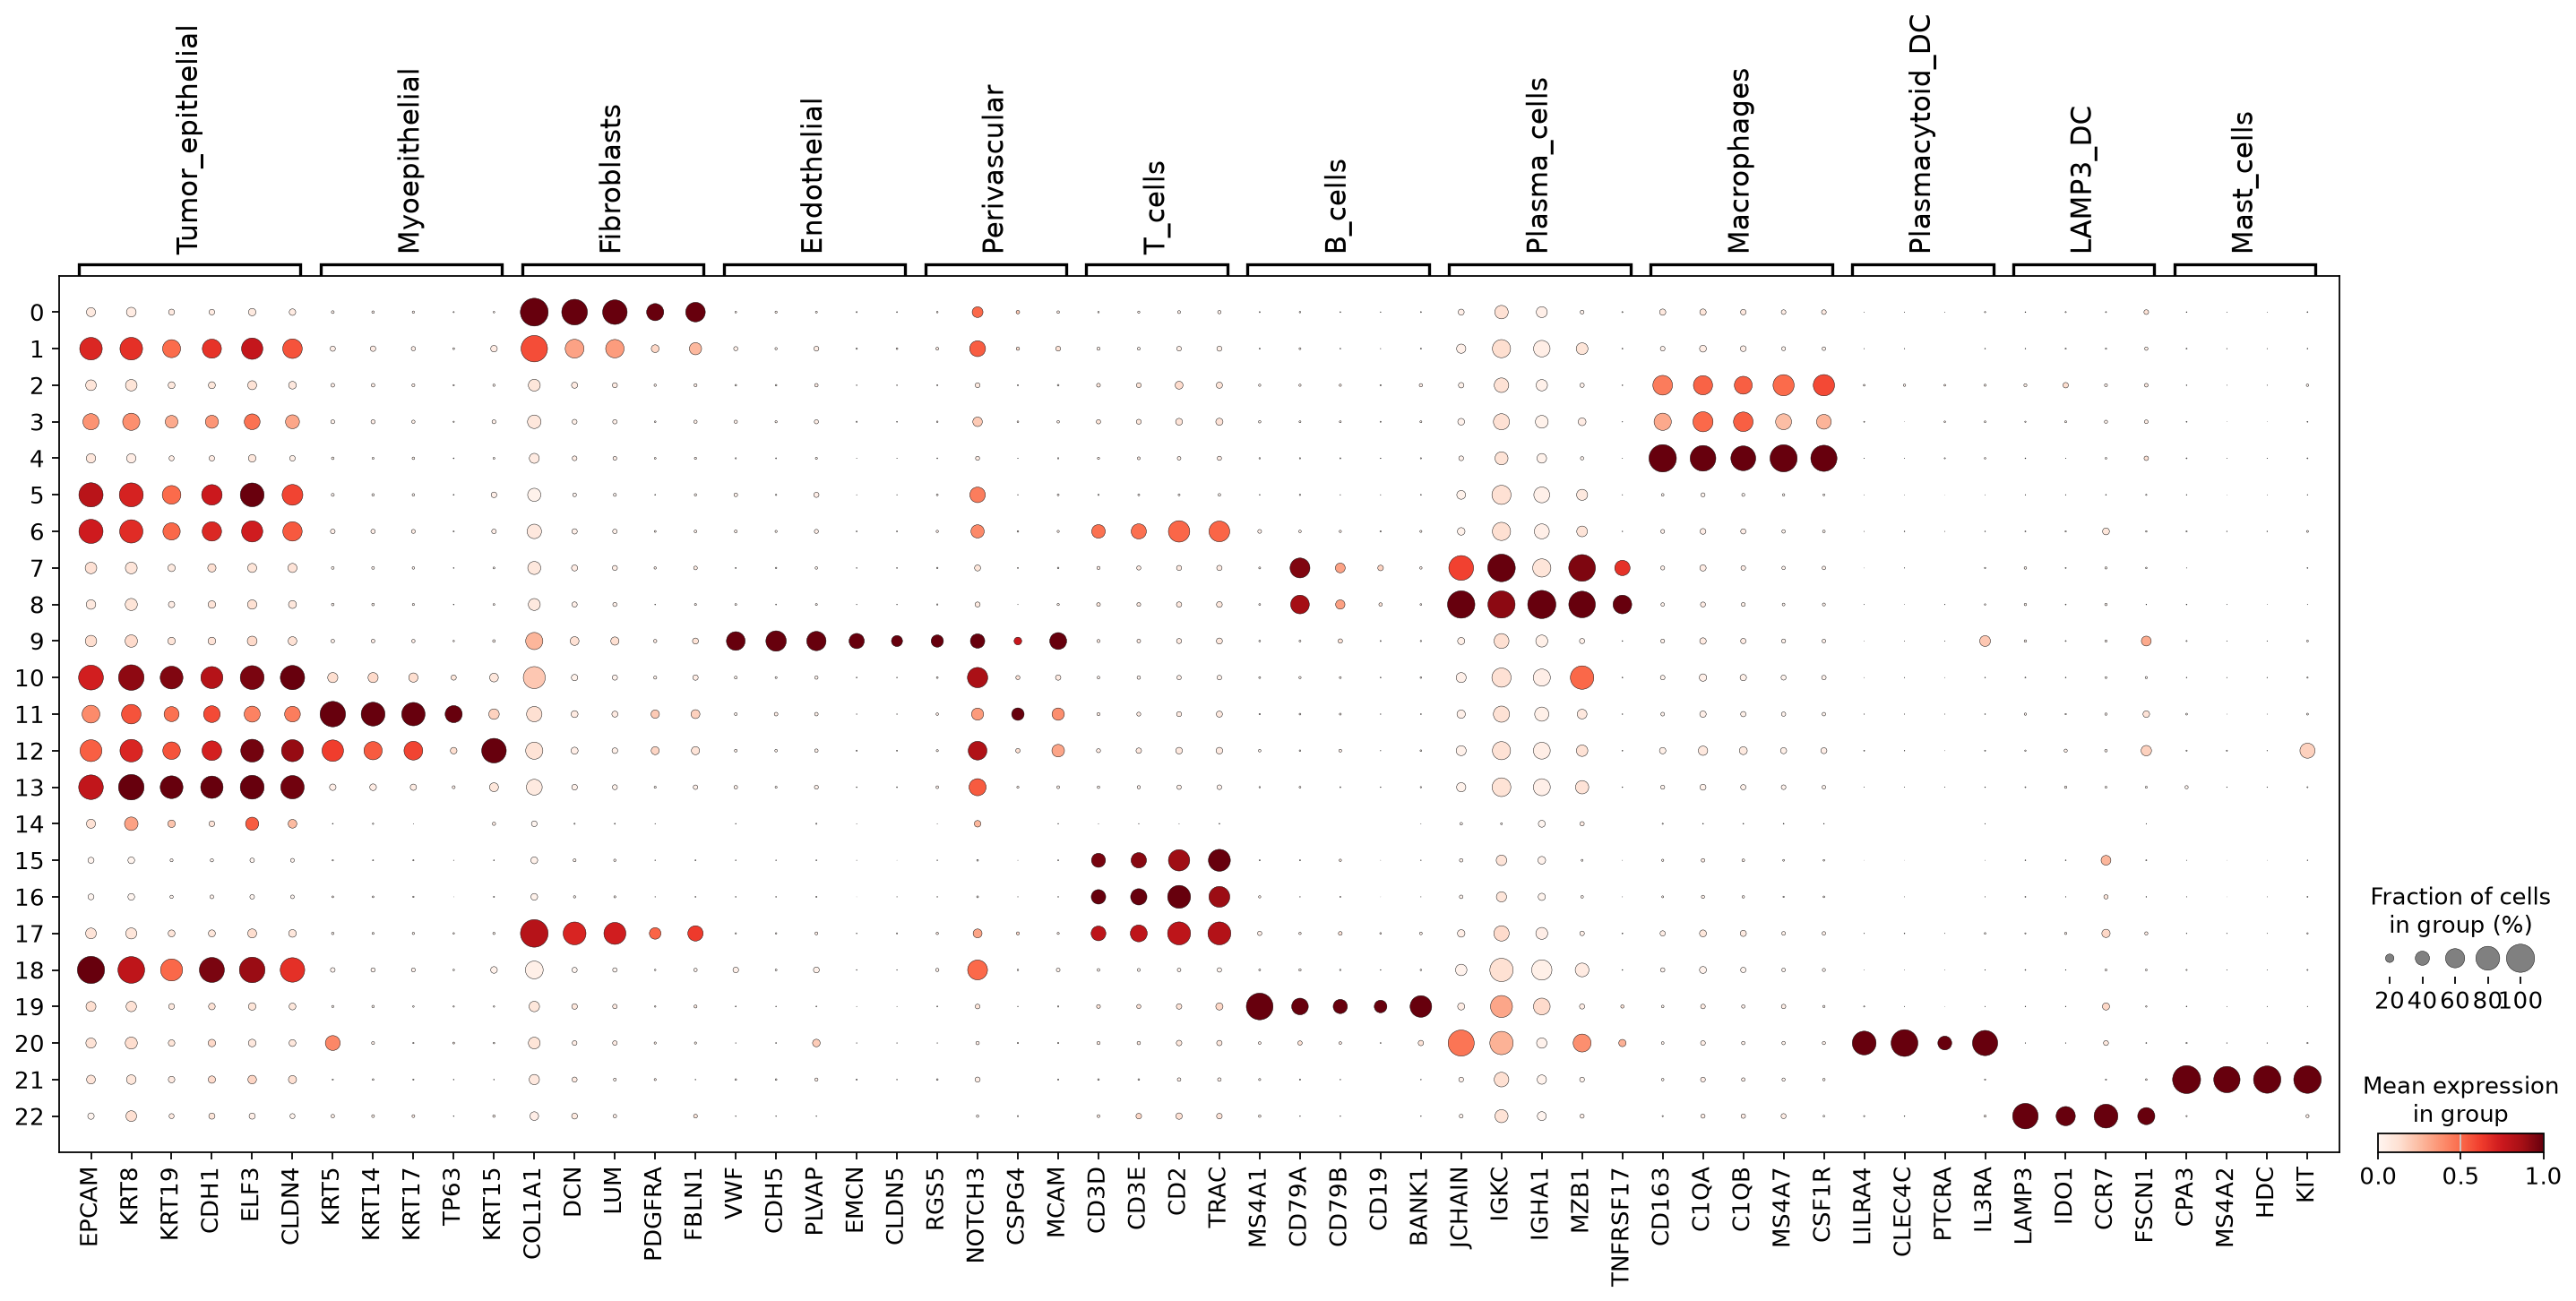

In [56]:
# Expression of the curated markers in each cluster (one row per cluster, genes grouped by cell type).
# Dot size = fraction of cells of the cluster expressing the gene;
# colour = mean expression, scaled from 0 to 1 per gene (standard_scale="var") so every gene is readable.
sc.pl.dotplot(adata, markers, groupby="leiden", standard_scale="var")

**Observations.** Most clusters have a single block of dark dots, consistent with 7a, and the three rare populations (20, 21, 22) express their markers exclusively. Some rows have **two** blocks:
- 11 and 12: myoepithelial **and** epithelial markers, which is biological (myoepithelial cells are epithelial cells);
- 9: endothelial **and** perivascular markers: the few perivascular cells are merged into the endothelial cluster, so **no cluster is called Perivascular**;
- **1** (fibroblast + epithelial), **6** (epithelial + T cell) and **17** (fibroblast + T cell): doublet-like profiles.

Cluster 14 only has small, pale dots, even for epithelial markers.

### 7c. Automatic annotation from marker scores

Same method as the pipeline: one score per cell and per cell type, averaged per cluster; each cluster takes the type with the highest mean score. The method can only choose **one** type per cluster and has no "doublet" option.

In [57]:
# Score of each cell for each cell type: mean expression of the type's markers minus the mean
# expression of random control genes with a similar expression level (positive = markers above background)
for ct, genes in markers.items():
    sc.tl.score_genes(adata, genes, score_name=f"score_{ct}", random_state=SEED)

# Mean score of each cell type in each cluster (one row per cluster, one column per cell type)
score_cols = [f"score_{ct}" for ct in markers]
cluster_scores = adata.obs.groupby("leiden", observed=True)[score_cols].mean()
cluster_scores.columns = list(markers)
# Each cluster takes the cell type with the highest mean score (name of the column holding the row maximum)
cluster_to_type = cluster_scores.idxmax(axis=1)
cluster_scores.assign(type=cluster_to_type).round(2)

,Tumor_epithelial,Myoepithelial,Fibroblasts,Endothelial,Perivascular,T_cells,B_cells,Plasma_cells,Macrophages,Plasmacytoid_DC,LAMP3_DC,Mast_cells,type
leiden,,,,,,,,,,,,,
0,-0.28,-0.08,2.27,-0.05,0.02,-0.20,-0.09,0.02,0.00,-0.03,-0.04,-0.03,Fibroblasts
1,0.36,-0.08,0.57,-0.05,-0.01,-0.39,-0.10,-0.09,-0.27,-0.03,-0.08,-0.03,Fibroblasts
2,-0.31,-0.09,-0.14,-0.06,-0.15,-0.15,-0.05,-0.07,1.24,0.01,0.04,-0.02,Macrophages
3,0.07,-0.08,-0.19,-0.04,-0.10,-0.19,-0.06,-0.08,0.78,-0.01,-0.03,-0.02,Macrophages
4,-0.28,-0.07,-0.11,-0.06,-0.12,-0.19,-0.07,-0.05,2.77,-0.00,-0.02,-0.02,Macrophages
5,0.46,-0.14,-0.42,-0.06,-0.07,-0.46,-0.10,-0.18,-0.35,-0.02,-0.09,-0.03,Tumor_epithelial
6,0.33,-0.10,-0.32,-0.05,-0.08,0.40,-0.07,-0.12,-0.31,-0.02,-0.02,-0.01,T_cells
7,-0.14,-0.06,-0.07,-0.04,-0.07,-0.16,0.27,2.60,-0.14,-0.01,-0.02,-0.02,Plasma_cells
8,-0.14,-0.05,-0.10,-0.03,-0.07,-0.12,0.24,4.32,-0.14,-0.01,-0.02,-0.02,Plasma_cells


cell_type
Tumor_epithelial    9180
T_cells             6270
Macrophages         4006
Fibroblasts         3700
Myoepithelial       1849
Plasma_cells        1468
Endothelial         1331
B_cells             1143
Plasmacytoid_DC      183
LAMP3_DC             130
Mast_cells           127
Name: count, dtype: int64


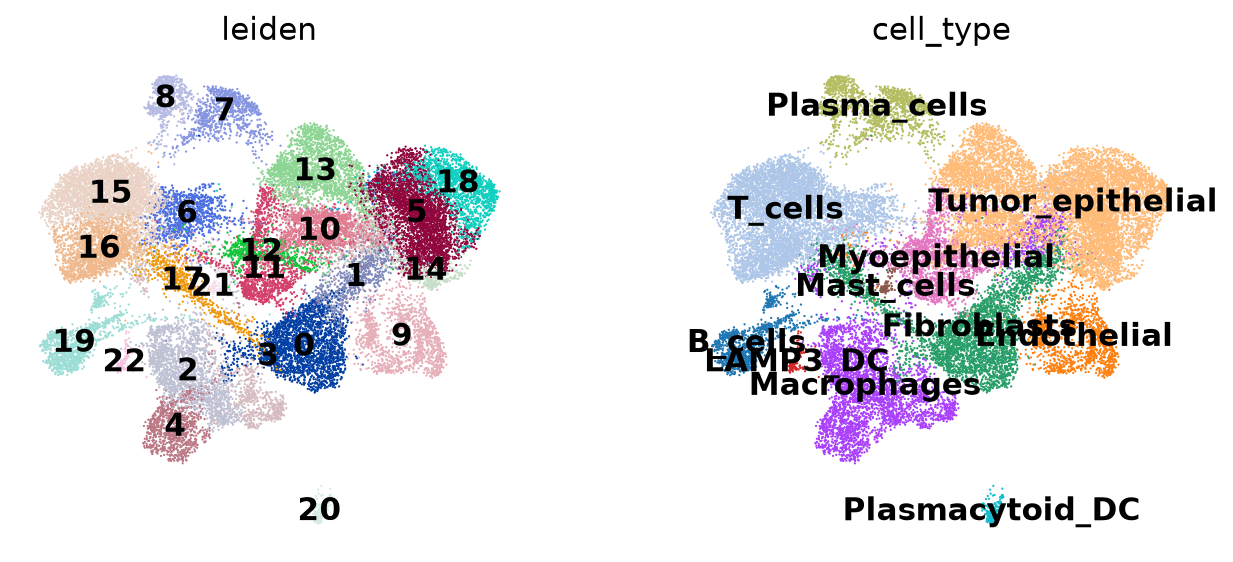

In [58]:
# Give every cell the type of its cluster, then draw the UMAP coloured by cluster and by type
adata.obs["cell_type"] = adata.obs["leiden"].map(cluster_to_type).astype("category")
print(adata.obs["cell_type"].value_counts())
sc.pl.umap(adata, color=["leiden", "cell_type"], legend_loc="on data", ncols=2, show=False)
plt.savefig(FIG / "01_umap_cell_types.png", dpi=150, bbox_inches="tight")
plt.show()

**Observations.** All curated types except Perivascular are found. As expected, the doublet-like clusters received the type of their dominant component: 1 and 17 → Fibroblasts (scores 0.57 vs 0.36 for tumour; 1.52 vs 1.04 for T cells), 6 → T_cells (0.40 vs 0.33 for tumour). Cluster 14 is called Tumor_epithelial with a very low score (0.06, against 0.46-0.79 for the other tumour clusters).

### 7d. Suspicious clusters

Three independent checks: QC metrics per cluster, overlap with the 10x hybrid labels, and a direct comparison of cluster 1 with the other fibroblasts (cluster 0).

In [59]:
# Median QC metrics per cluster ("typical" cell of each cluster).
# observed=True: only the clusters that actually exist
adata.obs.groupby("leiden", observed=True)[["doublet_score", "pct_counts_mt", "n_genes_by_counts"]].median().round(2)

,doublet_score,pct_counts_mt,n_genes_by_counts
leiden,,,
0,0.03,0.93,1125.0
1,0.10,3.22,2742.0
2,0.04,1.24,1623.5
3,0.07,2.38,1405.0
4,0.02,0.89,1146.0
5,0.03,3.55,3082.5
6,0.12,3.52,2625.0
7,0.02,1.02,1293.0
8,0.02,1.02,1246.0


In [60]:
# Fraction of each cluster that 10x labelled as hybrid (mean of a True/False column = fraction of True).
# label_10x was added in section 3b. Hybrids are ~5 % of all cells.
hybrid = adata.obs["label_10x"].str.contains("Hybrid")
hybrid.groupby(adata.obs["leiden"], observed=True).mean().round(2).sort_values(ascending=False).head(8)

leiden
6     0.65
17    0.58
15    0.06
8     0.03
16    0.02
3     0.01
1     0.01
21    0.01
Name: label_10x, dtype: float64

In [61]:
# What distinguishes cluster 1 from the other fibroblasts? Compare cluster 1 to cluster 0 only
# (instead of all other cells). key_added keeps the per-cluster results of 7a intact.
sc.tl.rank_genes_groups(adata, groupby="leiden", groups=["1"], reference="0",
                        method="wilcoxon", key_added="c1_vs_c0")
# logfoldchanges is in log2 (3.3 means ~10 times higher); pvals_adj is corrected for multiple testing
sc.get.rank_genes_groups_df(adata, group="1", key="c1_vs_c0").head(15)

,names,scores,logfoldchanges,pvals,pvals_adj
0,ERBB2,34.945328,3.529255,1.524846e-267,2.586444e-263
1,DCAF7,31.992947,3.477579,1.366777e-224,3.311896e-221
2,MIEN1,31.531246,3.386559,3.241487e-218,6.872763e-215
3,PGAP3,31.306818,3.436682,3.768624e-215,7.102600e-212
4,FASN,30.581993,3.242517,2.124521e-205,3.603613e-202
5,STARD3,29.936165,3.244759,6.661367e-197,1.027183e-193
6,CYB561,29.696522,3.216630,8.515080e-194,1.111021e-190
7,ANKRD30A,29.422781,3.867872,2.807837e-190,3.175102e-187
8,MLPH,28.382103,3.528363,3.363198e-177,3.565410e-174
9,MT-CO3,27.851879,1.995439,1.022120e-170,1.019836e-167


In [62]:
# Size of each cluster, and the 10x labels of the cells of cluster 1
print(adata.obs["leiden"].value_counts().sort_index())
adata.obs.loc[adata.obs["leiden"] == "1", "label_10x"].value_counts().head()

leiden
0     2291
1      788
2     1900
3     1118
4      988
5     3566
6     1004
7      887
8      581
9     1331
10    1472
11    1246
12     603
13    2132
14     406
15    3437
16    1829
17     621
18    1604
19    1143
20     183
21     127
22     130
Name: count, dtype: int64


label_10x
Stromal                  329
Invasive Tumor           198
Prolif Invasive Tumor     74
DCIS 1                    60
no label                  51
Name: count, dtype: int64

**Observations.**

| cluster | cells | median doublet score | 10x hybrids | evidence | conclusion |
|---|---|---|---|---|---|
| 6 | 1,004 | **0.12** | **65 %** | T-cell and tumour genes; 2,625 genes (T cells alone: ~750); tumour-like MT fraction | T + tumour doublets |
| 17 | 621 | **0.09** | **58 %** | fibroblast and T-cell markers | fibroblast + T doublets |
| 1 | 788 | **0.10** | 1 % | vs cluster 0: the top 15 genes are all tumour genes (ERBB2 amplicon, MUC1, FASN), ~10× higher; 2.4× more genes; tumour-like MT fraction | fibroblast + tumour doublets |
| 14 | 406 | 0.02 | – | 647 genes (tumour: ~3,000) and almost no MT RNA (0.36 %) | low-quality tumour cells (possibly stripped nuclei) |

Cluster 1 has few 10x hybrids because 10x defined no "stromal + tumour" hybrid category: such doublets could only be labelled Stromal (see section 8). Other clusters have median doublet scores of 0.01-0.07 (macrophages of cluster 3: 0.07), including clusters 9 and 12, whose two-type marker profiles are biological.

**Rule for the pipeline**: cluster numbers change between runs, so the pipeline needs a rule instead of a list. A **median doublet score ≥ 0.08** flags exactly clusters 1, 6 and 17.

### 7e. Final annotation

Doublet and low-quality clusters keep their cells in the object, with their own label, so they can be compared with the 10x labels; they are **excluded from the RCTD reference** (day 4), which must contain clean profiles.

In [63]:
# Clusters flagged in 7d: doublet score, 10x hybrids and two-type marker profiles (1, 6, 17);
# very few detected genes and almost no MT RNA (14)
DOUBLET_CLUSTERS = ["1", "6", "17"]
LOW_QUALITY_CLUSTERS = ["14"]

# Copy the automatic cluster -> type mapping (keeps the original intact), then overwrite the flagged clusters
final_types = cluster_to_type.copy()
final_types[DOUBLET_CLUSTERS] = "Doublets"
final_types[LOW_QUALITY_CLUSTERS] = "Low_quality"
adata.obs["cell_type"] = adata.obs["leiden"].map(final_types).astype("category")
adata.obs["cell_type"].value_counts()

cell_type
Tumor_epithelial    8774
T_cells             5266
Macrophages         4006
Doublets            2413
Fibroblasts         2291
Myoepithelial       1849
Plasma_cells        1468
Endothelial         1331
B_cells             1143
Low_quality          406
Plasmacytoid_DC      183
LAMP3_DC             130
Mast_cells           127
Name: count, dtype: int64

**Final annotation**: Tumor_epithelial 8,774 · T_cells 5,266 · Macrophages 4,006 · Doublets 2,413 · Fibroblasts 2,291 · Myoepithelial 1,849 · Plasma_cells 1,468 · Endothelial 1,331 · B_cells 1,143 · Low_quality 406 · Plasmacytoid_DC 183 · LAMP3_DC 130 · Mast_cells 127.

Without step 7e, more than a third of the "fibroblasts" (1,409 of 3,700) would have been doublets. Together with the 711 cells removed by Scrublet, ~10 % of the cells are doublets, plausible for ~30,000 loaded cells. Strategy: a conservative Scrublet threshold that keeps real cells, then doublet clusters identified from several independent signals.

Limits: no Perivascular type (merged with endothelium); a single tumour type (DCIS and invasive tumour are not separated).

## 8. Comparison with the published 10x labels

10x published its own annotation of these cells (sheet `scFFPE-Seq`). `pd.crosstab` counts the cells of each pair (my type, 10x label); normalised by column, each column reads: "of the cells that 10x called X, which fraction did I call Y?". A single dark cell per column means agreement.

Caveat: the curated markers were selected with the help of these labels (`assets/MARKERS.md`), so the comparison is not fully independent; disagreements are the most informative part.

cells without a published label: 2623


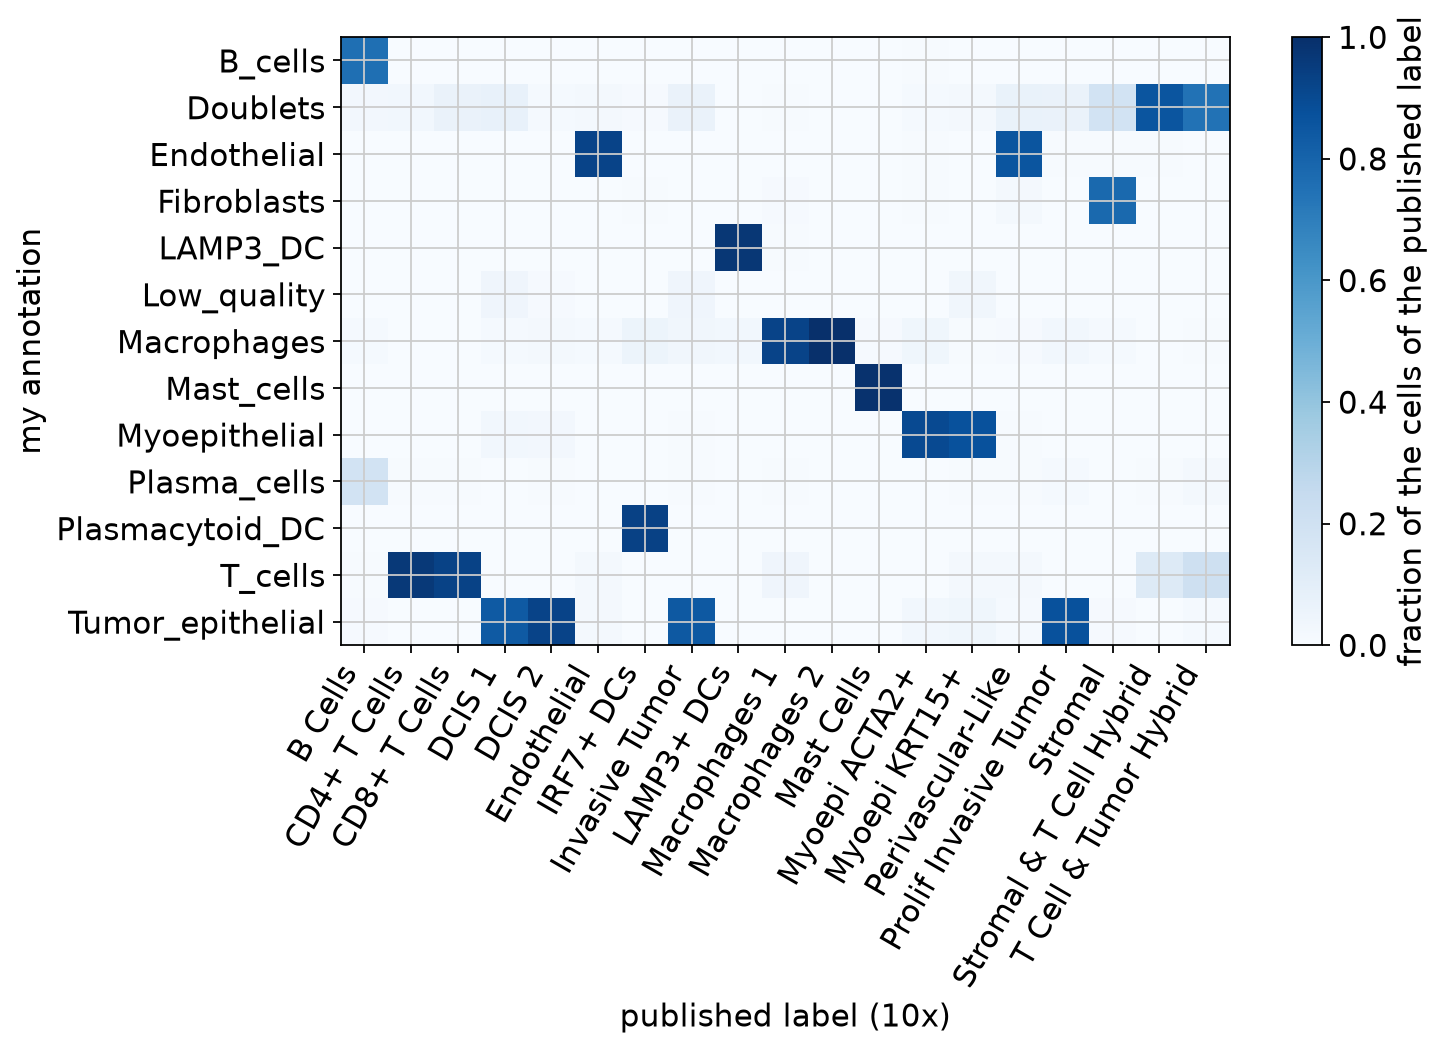

In [64]:
# 10x labels in the order of our cells (unlabelled cells -> NaN, ignored by crosstab)
labels = pd.read_excel(DATA / "annotations" / "Cell_Barcode_Type_Matrices.xlsx", sheet_name="scFFPE-Seq")
labels = labels.set_index("Barcode")["Annotation"]
adata.obs["published_label"] = labels.reindex(adata.obs_names).astype("category")
print("cells without a published label:", adata.obs["published_label"].isna().sum())

# Rows = my annotation, columns = 10x labels; each column sums to 1
crosstab = pd.crosstab(adata.obs["cell_type"], adata.obs["published_label"], normalize="columns")

# Heatmap of the table: the darker the cell, the larger the fraction of the 10x label
fig, ax = plt.subplots(figsize=(10, 5))
im = ax.imshow(crosstab.values, cmap="Blues", vmin=0, vmax=1)
ax.set_xticks(range(crosstab.shape[1]), crosstab.columns, rotation=60, ha="right")
ax.set_yticks(range(crosstab.shape[0]), crosstab.index)
ax.set_xlabel("published label (10x)")
ax.set_ylabel("my annotation")
fig.colorbar(im, label="fraction of the cells of the published label")
fig.savefig(FIG / "01_annotation_vs_published.png", dpi=150, bbox_inches="tight")

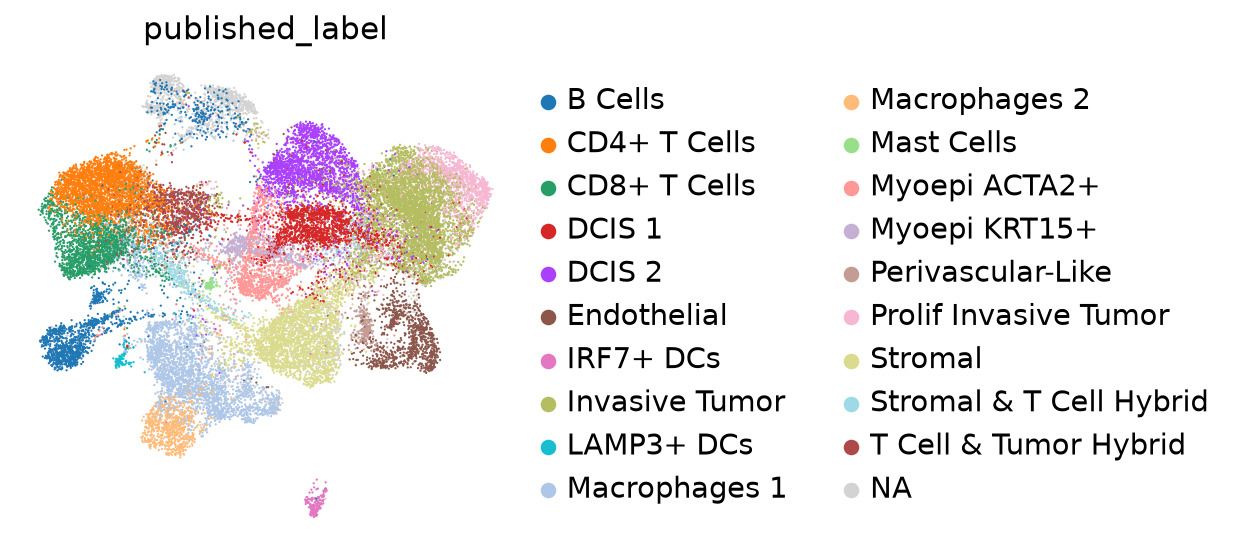

In [65]:
# The same UMAP coloured by the 10x labels: where are their hybrids, and our doublet clusters?
sc.pl.umap(adata, color="published_label", ncols=1)

**Observations.** Agreement with the 10x labels is high (≈ 80-100 % per label). Differences are mostly granularity: 10x splits T cells (CD4/CD8), macrophages (1/2), myoepithelial cells (ACTA2+/KRT15+) and tumour cells (DCIS 1, DCIS 2, invasive, proliferating), while this annotation keeps one type each; conversely it separates **plasma cells** from B cells (~20 % of the 10x "B Cells"). Perivascular-like cells fall into Endothelial. Both 10x hybrid labels fall mostly into **Doublets** (~85 % of Stromal & T Cell Hybrid, ~70 % of T Cell & Tumor Hybrid), and ~20 % of the 10x **Stromal** cells are the fibroblast-tumour doublets of cluster 1, for which 10x had no category.

## 9. Saving

The annotated object (raw counts in `layers["counts"]`, cell types in `obs["cell_type"]`) is the reference for the deconvolution of the Visium spots (notebook 03). `.h5ad` files are excluded from git by `.gitignore`: they are large and can be regenerated.

In [66]:
# Write the annotated AnnData object to disk (HDF5 format)
adata.write_h5ad(DATA / "sc_annotated.h5ad")
print("saved:", DATA / "sc_annotated.h5ad", "|", adata)

saved: /home/juliette/projets/sc-spatial-breast-cancer/data/sc_annotated.h5ad | AnnData object with n_obs × n_vars = 29387 × 16962
    obs: 'n_genes_by_counts', 'total_counts', 'total_counts_mt', 'pct_counts_mt', 'label_10x', 'n_genes', 'doublet_score', 'predicted_doublet', 'leiden_0.4', 'leiden_0.8', 'leiden_1.2', 'leiden', 'score_Tumor_epithelial', 'score_Myoepithelial', 'score_Fibroblasts', 'score_Endothelial', 'score_Perivascular', 'score_T_cells', 'score_B_cells', 'score_Plasma_cells', 'score_Macrophages', 'score_Plasmacytoid_DC', 'score_LAMP3_DC', 'score_Mast_cells', 'cell_type', 'published_label'
    var: 'gene_ids', 'feature_types', 'genome', 'mt', 'n_cells_by_counts', 'mean_counts', 'pct_dropout_by_counts', 'total_counts', 'n_cells', 'highly_variable', 'means', 'dispersions', 'dispersions_norm'
    uns: 'scrublet', 'log1p', 'hvg', 'pca', 'neighbors', 'umap', 'leiden_0.4', 'leiden_0.8', 'leiden_1.2', 'leiden_0.4_colors', 'leiden_0.8_colors', 'leiden_1.2_colors', 'rank_genes_gro